# Drone VI: renormalising generative models for active vision

This notebook walks the **Drone VI** demonstration of **renormalising generative models (RGMs)** for discrete active inference in a dynamic 3D scene. A voxel world with animate motion is generated under a process model; an RGM hierarchy is learned from place-level class trajectories by fast structure learning; the hierarchy is coupled back to a drone active-vision model (ray- and pose-dependent outcomes) so deeper levels supply empirical priors over place dynamics while drone pose remains controllable; hierarchical inference then supports **surveillance** and short-horizon **wayfinding**, ending in a behaviour movie.

Notation follows our RGM paper (*Renormalising Generative Models for Active Inference*). Equations are rendered in LaTeX and tied to the **variables created in each cell**.

**Runtime.** Structure learning and variational message passing dominate later cells; expect a nontrivial run for a full notebook pass.

### Cell 0 — Environment setup

This cell prepares the **local** environment: locates the RGMs repository root, places it on the Python path, imports the DEM library and plot helpers (including display helpers for later figures and the behaviour MP4), sets the random seed, and creates the figure/video output directory.

Install dependencies once beforehand from the repository root with `python -m pip install -r requirements.txt` (this includes `imageio` / `imageio-ffmpeg` for the behaviour movie). This cell does **not** clone the repository or run `pip install`.


In [1]:
import copy
import sys
import time
from pathlib import Path

from IPython.display import Image, Video, display


def _find_repo_root() -> Path:
    """Locate the RGMs checkout (expects python_src/ and requirements.txt)."""
    start = Path.cwd().resolve()
    for cand in [start, *start.parents]:
        if (cand / "python_src").is_dir() and (cand / "requirements.txt").is_file():
            return cand
    raise FileNotFoundError(
        "Could not find the RGMs repository root (python_src/ and "
        "requirements.txt). Open this notebook from a local checkout after "
        "installing dependencies with: python -m pip install -r requirements.txt"
    )


REPO = _find_repo_root()
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib

matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import numpy as np

from python_src.toolbox.DEM.dem_drone_vi_lib import (
    assemble_mdp_and_gdp_from_scene,
    assemble_Q_from_pdp,
    build_pdp_wayfinding,
    map_from_drone_D,
    pack_mdp_ida_linked,
    scene_dict_from_unity_sizes,
    spm_drone_unity,
    _mdp_levels_for_a2A,
)
from python_src.toolbox.DEM.dem_drone_vi_plot_true_env_early import (
    dem_drone_vi_plot_true_env_early,
)
from python_src.toolbox.DEM.spm_behaviour import spm_behaviour
from python_src.toolbox.DEM.spm_MDP_generate import spm_MDP_generate
from python_src.toolbox.DEM.dem_drone_vi_plot_true_scene_post_generate import (
    dem_drone_vi_plot_true_scene_post_generate,
)
from python_src.toolbox.DEM.spm_faster_structure_learning import (
    spm_faster_structure_learning,
)
from python_src.toolbox.DEM.dem_drone_vi_plot_mdp_params import dem_drone_vi_plot_mdp_params
from python_src.toolbox.DEM.optim2full_native_plot import mdp_fsl_end
from python_src.toolbox.DEM.spm_MDP_VB_XXX import spm_MDP_VB_XXX
from python_src.toolbox.DEM.spm_mdp_a2A import spm_mdp_a2A
from python_src.toolbox.DEM.spm_mdp2rdp import spm_mdp2rdp
from python_src.toolbox.DEM.dem_drone_vi_plot_rgm import dem_drone_vi_plot_rgm
from python_src.toolbox.DEM.spm_Q2mdp import spm_Q2mdp
from python_src.toolbox.DEM.dem_drone_vi_plot_active_inference import (
    dem_drone_vi_plot_active_inference,
)
from python_src.toolbox.DEM.dem_drone_vi_plot_wayfinding import dem_drone_vi_plot_wayfinding

# MATLAB DEM_drone_VI.m ~L54: rng(1)
np.random.seed(1)

out_dir = REPO / "visualizations" / "DEM_drone_VI"
out_dir.mkdir(parents=True, exist_ok=True)
print("REPO=", REPO, flush=True)


REPO= C:\Users\andre\.cursor\RGMs


### Cell 1 — True 3D environment

This cell builds the **true inanimate scene**—a discrete 3D world of categorical places—before any generative process, structure learning, or drone planning.

#### Scene sizes and geometry parameters

The notebook fixes an $N_x\times N_y\times N_z$ voxel lattice and related vision/control sizes, stored both as scalars and in the geometry dict **`PG`**:

| Symbol / code | Role in this demo |
|---------------|-------------------|
| `Nx`,`Ny`,`Nz` $=32,32,8$ | Environment size (places on a rectangular grid) |
| `Nc` $=8$ | Number of place **classes** |
| `Nr` $=16$ | Rays along each FOV axis ($N_g=N_r^2$ lines of sight later) |
| `Nd` $=16$ | Maximum ray **depth** (bins along a line of sight) |
| `Na` $=12$ | Discrete drone **heading** angles |
| `Ns` $=6$ | FOV partitioning used to place ray angles |
| `Nu` $=4$ | Controllable drone factors ($x,y,z$, heading) |
| `No` $=1$ | Number of animate objects (introduced in the process next) |

In paper language, each place $\ell\in\{1,\ldots,N_p\}$ with $N_p=N_x N_y N_z$ carries a categorical class $c_\ell\in\{1,\ldots,N_c\}$.

#### Building `D`, `W`, and `MAP`

The call

`D, W = spm_drone_unity(Nx, Ny, Nz, Nc)`

constructs:

- **`W`** — an `Nx×Ny×Nz` array of **integer class labels** at each voxel.
- **`D`** — the same layout as a cell of length-$N_c$ one-hot columns (one categorical distribution per voxel).

Then

`MAP = map_from_drone_D(D)`

flattens **`D`** into a length-$N_p$ list of one-hots (column-major order over the grid). **`MAP`** is the place-wise categorical field used by the early figure and later packing helpers.

Typical class codes written into **`W`** in this demo (1-based labels among `Nc` classes):

- **1** — empty space (default background)
- **2** — water / pond base
- **3** — land / grass
- **4** — foliage
- **5** — pillars
- **7** — building / brick volume
- **8** — a target marker (placed in the pond region)

Animate occupancy (a movable “thing”) is **not** baked into this static `W`; it enters when the generative process adds an object factor (next cells). Static classes are the permanent scene structure that FSL will treat as rarely changing places; empty places are those that *can* become occupied by movable classes.

#### Why this scene matters

Places on this lattice are the spatial sites that fast structure learning will renormalise. The early figure checks that Unity-like construction, class colours, and the flattened **`MAP`** agree before we attach ray likelihoods or sample dynamics.

#### Figure: true environment

`dem_drone_vi_plot_true_env_early(MAP, W, Nx=…, Ny=…, Nz=…, Nc=…)` draws, from **`MAP`** and **`W`**:

1. **2D panel — “True environment”.** A colour rendering of the place field via the one-hots in **`MAP`** (projected with the demo’s show-$x$ colour map).
2. **3D panel.** Scatter of non-empty voxels (`W` class $\ge 2$), coloured by class, on the $N_x\times N_y\times N_z$ lattice.

Together these panels are the ground-truth scene the process will animate and the drone will later observe through rays.

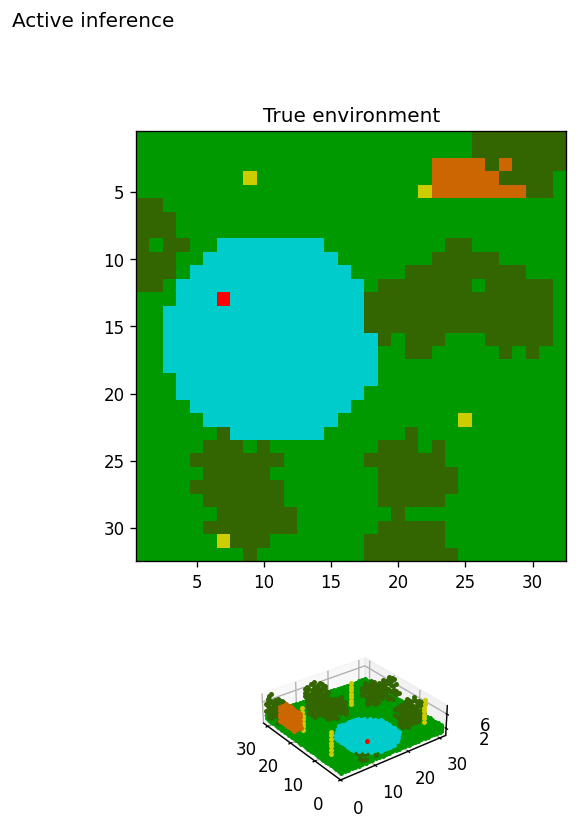

In [2]:
Nx = Ny = 32
Nz = 8
Nd = 16
Nc = 8
Nr = 16
Na = 12
No = 1
Nu = 4
Ns = 6

PG = {"Nx": float(Nx),"Ny": float(Ny),"Nz": float(Nz),"Nd": float(Nd),"Nc": float(Nc),"Nr": float(Nr),"Na": float(Na),"No": float(No),"Nu": float(Nu),"Ns": float(Ns),}

D, W = spm_drone_unity(Nx, Ny, Nz, Nc)

MAP = map_from_drone_D(D)

png_path = out_dir / "DEM_drone_VI_colab2_true_env_early.png"
written = dem_drone_vi_plot_true_env_early(MAP, W, Nx=Nx, Ny=Ny, Nz=Nz, Nc=Nc, save_png=True, png_path=png_path, fig_title="Active inference", )

assert written is not None and Path(written).is_file(), written
display(Image(filename=str(written)))

### Cell 2 — Generative process and drone generative model

This cell turns the Unity scene into two related discrete generative structures used for different jobs:

`scene = scene_dict_from_unity_sizes(..., W=W)` then  
`built = assemble_mdp_and_gdp_from_scene(scene)` → **`mdp`**, **`GDP`**, **`PG`**, **`Np`**, **`Ng`**, **`V`**, **`s_mdp`**, **`s_gdp`**.

#### Two structures from one scene

- **`GDP`** — generative **process**: used next to **sample** place/object trajectories for structure learning (`GDP["T"]` horizon; process likelihoods `GDP["A"]`, transitions `GDP["B"]`, initial latents `GDP["s"]`).
- **`mdp`** — drone generative **model** scaffold: pose-dependent vision + telemetry likelihoods and controllable pose transitions, kept for later packing when the learned RGM is coupled to active vision (`mdp["A"]`, `mdp["B"]`, `mdp["D"]`, `mdp["id"]`, …).

They share the same place physics and ray geometry, but play different roles (process vs agent model). Initial object pose differs by design: training start **`s_gdp`** vs model start **`s_mdp`** (animate object placed differently so generation and later inference are not trivially identical copies).

#### Pose, FOV, and rays in `PG`

**`PG`** holds the global geometry used by functional likelihoods:

- drone headings **`PG["phi"]`** (`Na` angles around the yaw circle);
- ray angles **`PG["FOV"]`** across a finite field of view (`Ns` partitions → `Nr` samples);
- sizes `Nx,Ny,Nz,Nd,Nc,Nr,Na,Nu,No`.

The number of visual **lines of sight** is

$$
N_g = N_r^2
\quad(\texttt{Ng}=N_r\cdot N_r\text{ in code}).
$$

Each ray contributes **two** outcome modalities in the process/model: a **depth** outcome and a **class** outcome (so $2N_g$ visual streams), plus **telemetry** modalities that report drone $x,y,z$, and heading (identity maps on those factors).

#### Latent factors

In this demo the latent state stacks:

1. **Controllable drone factors** (`Nu=4`): location $x,y,z$ and heading $a$, with path-conditioned transitions in **`GDP["B"]`** / **`mdp["B"]`** (perimeter/floor constraints; small transition noise on some axes).
2. **Per-place class factors** ($N_p$ factors): categorical class at each voxel (Dirichlet / identity-like local dynamics for static structure).
3. **Animate object factors** (`No`): object pose/class appended on the **process** side so generation can move a “thing” through the scene.

Controllability for planning is marked on the drone factors (`mdp["U"]`); during **training generation** the process disables exploration of those controls (`GDP["U"]` is zeroed) so the RGM corpus is driven by place/object dynamics rather than drone flight.

#### Domain factors and functional likelihoods

Outcomes along a ray are **not** stored as one giant explicit $A$ tensor over every place in the world. Given drone pose, projective geometry selects the **parent places along that line of sight**. Depth and class outcomes are then the state of the **first non-empty** location along the ray (empty = class $1$); if the ray hits nothing within `Nd`, depth reports “far / empty.”

In paper notation the categorical likelihood still has the usual meaning

$$
p\big(o^{g}\,\big|\,s_{\mathrm{pa}(g)}\big),
$$

but here $s_{\mathrm{pa}(g)}$ are the **domain** parents for modality $g$ (drone pose plus places—or object slots—along ray $g$), and the map is evaluated **functionally** for the current view. In code those maps live as callables in **`GDP["A"]`** / **`mdp["A"]`** (depth and class per ray), with parent selection via the geometry hook installed in **`mdp["id"]`** / **`GDP["id"]`**.

Path-conditioned motion of controllable factors has the standard discrete form

$$
p(s_{\tau+1}=i\mid s_{\tau}=j,\,u_{\tau}=h,\,B)=B_{ijh},
$$

with slices in **`GDP["B"]`** and **`mdp["B"]`**.

#### Controllability vs place dynamics (foreshadow)

Later, deeper RGM levels will supply **empirical priors over place** dynamics (object permanence and motion). Drone pose factors remain the ones planning can **control**. This cell only assembles the process and the drone-level scaffold that make that split possible.

In [3]:
scene = scene_dict_from_unity_sizes(
    Nx=int(Nx),
    Ny=int(Ny),
    Nz=int(Nz),
    Nd=int(Nd),
    Nc=int(Nc),
    Nr=int(Nr),
    Na=int(Na),
    No=int(No),
    Nu=int(Nu),
    Ns=int(Ns),
    W=W,
)

built = assemble_mdp_and_gdp_from_scene(scene)
mdp = built["mdp"]
GDP = built["GDP"]
PG = built["PG"]
Np = int(built["Np"])
Ng = int(built["Ng"])
V = built["V"]
s_mdp = built["s_mdp"]
s_gdp = built["s_gdp"]

assert built.get("lane") == "native", built.get("lane")
assert isinstance(mdp, dict) and "A" in mdp and "B" in mdp and "id" in mdp
assert isinstance(GDP, dict) and "A" in GDP and "B" in GDP and "T" in GDP
assert isinstance(PG, dict) and "Nx" in PG

### Cell 3 — Generate place dynamics and build `Q`

We now sample a trajectory from the generative **process** and reshape it into the multi-site evidence stream used by fast structure learning.

#### Process generation (no drone exploration)

With horizon **`GDP["T"] = 64`** and controllable drone paths disabled in **`GDP["U"]`**, the call

`PDP = spm_MDP_generate(GDP)`

draws latent trajectories and outcomes under the process. **`PDP["s"]`** stores the generated latent indices over time (drone pose, place classes, animate object); **`PDP["o"]`** / process outcomes follow the ray and telemetry likelihoods. For structure learning we care about the **place/object class trajectory**, not about flying the drone through the training corpus.

#### Assembling `Q` as level-1 evidence $Y^{(1)}$

`Q = assemble_Q_from_pdp(PDP, PG, Nu, No, Np)` builds an $N_p\times T$ cell of categorical distributions:

- for each place $f=1{:}N_p$ and time $t$, **`Q[f][t]`** is a length-`Nc` one-hot (or soft categorical) over class;
- animate objects **overwrite** the class at the place they occupy at time $t$.

In the paper’s renormalisation notation, site-level categorical observations entering the first RG step are $Y^{(1)}$. **In this notebook**, those sites are the 3D places and

$$
Y^{(1)}_{f,t}\;\longleftrightarrow\;\texttt{Q[f][t]}.
$$

The next cell will call fast structure learning on **`Q`** with spatial size **`S = [Nx, Ny, Nz]`**.

#### Figure: true scene after generation

`dem_drone_vi_plot_true_scene_post_generate(Q, PG, …)` renders the place field from **`Q`** (looping times internally; the saved PNG is the **final** frame). The panel titled “True scene” shows how classes occupy the $N_x\times N_y\times N_z$ lattice after process play—including motion of the animate object—before any hierarchical model is learned.

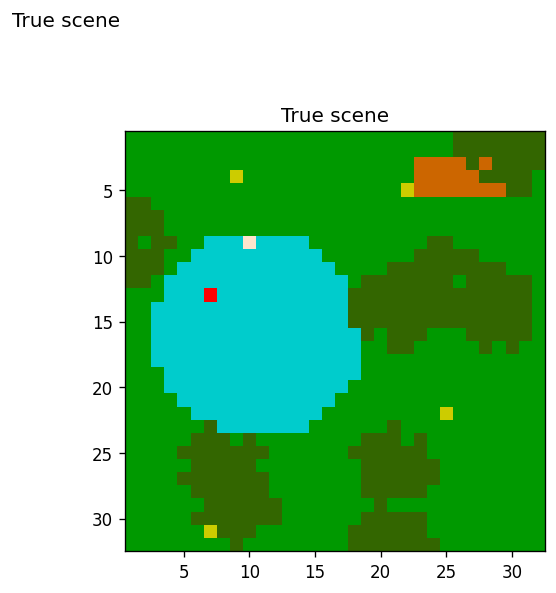

In [4]:
PDP = spm_MDP_generate(GDP)

Q = assemble_Q_from_pdp(PDP, PG, int(Nu), int(No), int(Np))

png_path = out_dir / "DEM_drone_VI_colab2_true_scene_post_generate.png"
written = dem_drone_vi_plot_true_scene_post_generate(Q, PG, save_png=True, png_path=png_path, fig_title="True scene", loop_all_t=True, )

assert written is not None and Path(written).is_file(), written
display(Image(filename=str(written)))

### Cell 4 — Fast structure learning on place dynamics

This cell builds a **hierarchical RGM** from the place/object class trajectories in **`Q`**. Unlike a pixel-game pipeline that may merge selected reward windows after a first pass, here a single call learns the hierarchy directly from the generated scene dynamics.

#### Renormalisation of the place sequence

Fast structure learning implements the constructive renormalisation step of the paper. At level $n$, observations over sites $i$, times $t$, and channels $c$ are written $Y^{(n)}_{i,t,c}$. One RG step learns a level model and emits coarser data for the next level:

$$
\mathcal{R}_n:\quad
Y^{(n)}
\longmapsto
\big(M^{(n)},\,Y^{(n+1)}\big).
$$

**In this notebook:**

- $Y^{(1)}$ is the multi-place categorical stream **`Q`** from Cell 3: one length-`Nc` distribution per place $f=1{:}N_p$ and time $t$, with animate objects overwriting the places they occupy.
- Spatial layout for grouping is the 3D lattice

$$
\texttt{S}=[N_x,\,N_y,\,N_z]
$$

  (in code: `S = [Nx, Ny, Nz]`).
- Scale caps for grouping are the vector

$$
\texttt{dx}=[1,\,64]
$$

  — a fine-then-coarse schedule on the voxel grid (first level groups tightly; a later level allows much larger spatial groups).
- **`MDP = spm_faster_structure_learning(Q, S, dx)`** applies a stack of $\mathcal{R}_n$ steps. The list **`MDP`** holds the learned levels $M^{(n)}$ (Dirichlet likelihood/transition cells **`a`**, **`b`**, and hierarchical ids). Coarser $Y^{(n+1)}$ are the upward state/path summaries built inside that routine.

#### Grouping places by temporal dependence

Places that share temporal structure are candidates to share a hidden cause. Pairwise dependence is summarised by a mutual-information matrix $I$ ($I_{ij}$ large when sites $i$ and $j$ co-vary over time). Group membership $z$ maximises shared structure under a size cap $dx_n$:

$$
\max_z\; z^\top I z,
\qquad
z_i\in\{0,1\},
\qquad
\sum_i z_i \le dx_n.
$$

The fast routine uses a spectral relaxation (principal eigenvector of $I$, then a hard group from the largest entries). **Here**, sites are the **places** on the $N_x\times N_y\times N_z$ lattice organised by **`S`**, with successive caps from **`dx`**.

#### Patterns become hidden states; $A$ and $B$ accumulate counts

Within a group $G_k^{(n)}$, recurring local occupancy/motion patterns among neighbouring places are labelled as latent states: $s^{(n)}_{k,t}=\ell$ means the configuration at time $t$ belongs to pattern class $\ell$. Soft evidence is binned by pattern similarity; upward summaries are typically hard one-hots $\hat s^{(n)}_{k,t}=e_\ell$.

State–outcome and state–transition–path counts update Dirichlet parameters

$$
\tilde a = a + N_A,
\qquad
\tilde b = b + N_B,
$$

so posterior means $\mu(\tilde a)$, $\mu(\tilde b)$ define local likelihoods $A$ and path-conditioned transitions $B_{ijh}$. **In code**, those countable tensors live in **`MDP[n]["a"]`** and **`MDP[n]["b"]`** at each level $n$.

#### Upward summaries and downward empirical priors

Each retained group passes state and path summaries to the next level at selected times $t_\tau$ (stride $dt_n$):

$$
Y^{(n+1)}_{k,\tau,1}=\hat s^{(n)}_{k,t_\tau},
\qquad
Y^{(n+1)}_{k,\tau,2}=\hat u^{(n)}_{k,t_\tau}.
$$

Read downward, higher-level likelihoods over those summaries become empirical priors $D$ and $E$ on child initial states and paths. As one ascends, the hierarchy encodes slower serial structure—**object permanence and movement** over places that can change, while static classes remain nearly fixed. In **`MDP`**, those vertical links are the hierarchical id / mapping structure among levels—the same parent–child interface used next when the drone model is coupled in.

#### What this call returns; parameters figure

After FSL, **`MDP`** is the list of levels. `mdp_fsl_end(MDP)` selects the deepest level **`MDP_end`** for visualisation.

`dem_drone_vi_plot_mdp_params(MDP_end, OPT="norm", …)` plots the **normalised** Dirichlet structure at that level (likelihood and transition geometry from **`a`/`b`**—or their normalised counterparts under `OPT="norm"`). The figure title names the plotted level (e.g. “Parameters: level …” corresponding to `len(MDP)`). It is a visual check that place dynamics have been compressed into countable hierarchical tensors before we re-attach drone vision.

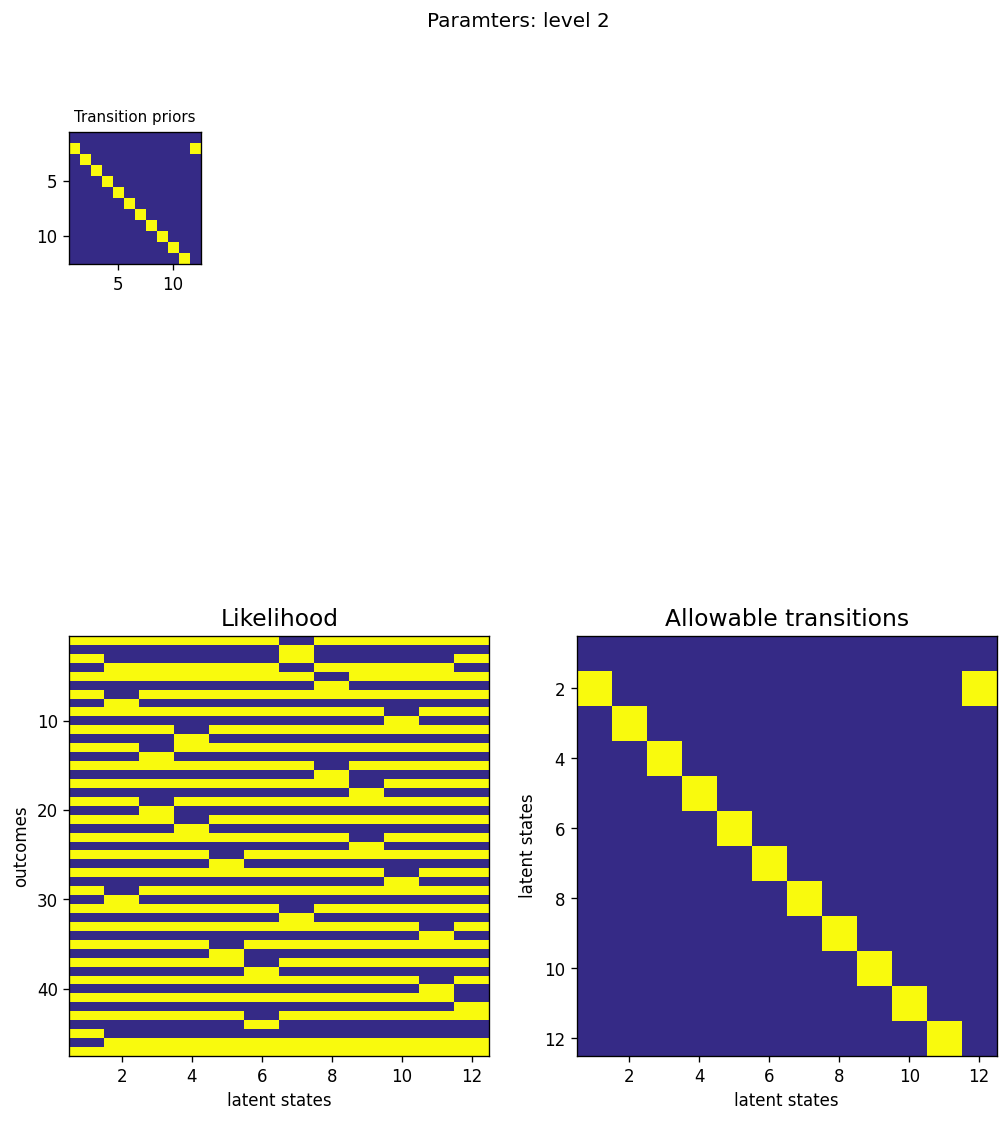

In [5]:
S = np.asarray([float(Nx), float(Ny), float(Nz)], dtype=np.float64)
dx = np.asarray([1.0, 64.0], dtype=np.float64)

MDP = spm_faster_structure_learning(Q, S, dx)

n_lev = len(MDP) if isinstance(MDP, list) else int(np.asarray(MDP, dtype=object).size)

MDP_end = mdp_fsl_end(MDP)

png_path = out_dir / "DEM_drone_VI_colab2_mdp_params.png"
written = dem_drone_vi_plot_mdp_params(MDP_end, OPT="norm", save_png=True, png_path=png_path, fig_title="Paramters: level 2", )
assert written is not None and Path(written).is_file(), written
display(Image(filename=str(written)))

### Cell 5 — Couple the RGM to active vision; surveillance

Deeper levels in **`MDP`** were learned from **place** trajectories. The drone, however, observes the world through **rays and telemetry**. This cell **completes** the RGM for active vision: replace/link the first level so pose-dependent outcomes meet RGM children, keep drone pose **controllable**, then run a short hierarchical solve (**surveillance**).

#### Completing the RGM: likelihoods that speak drone observations

1. **`MDP_a2A = spm_mdp_a2A(...)`** — normalises Dirichlet counts in the learned levels into usable likelihood/transition structure (`A`/`B`-style tensors) ready for hierarchical coupling.
2. **`mdp_p, mdp_levels, pack_meta = pack_mdp_ida_linked(mdp, mdp_levels_in, Nu=Nu)`** — links the drone model scaffold **`mdp`** (Cell 2) to the learned children:
   - place-factor transitions in **`mdp_p["B"]`** are rewritten so they live in the same outcome space as the RGM’s first-level likelihoods (the $A B A^\top$ style remapping in the packing loop);
   - parent indices **`mdp_p["id"]["D"]`** / **`E`** wire deeper RGM factors as empirical priors over those place factors;
   - drone $x,y,z$, heading factors (the first `Nu` factors) remain the agent’s **controllable** pose.
3. **`RDP = spm_mdp2rdp([mdp_p] + mdp_levels[1:])`** — nests packed level 0 with higher **`mdp_levels`** into one recursive structure **`RDP`**.

Effectively, knowledge of the known scene (what does not move, and how movable classes transit) sits in the hierarchical parameters linking level 2→1, while planning can still act on drone pose informed by predicted next world state.

#### Empirical priors over places; control over pose

In paper language, an RGM replaces a child’s initial-state prior by a parent-dependent empirical prior $D$ (and paths by $E$). **Here**, those links apply to the **place** latent states—not to the drone’s telemetry factors. Pose stays free for planning-as-inference at the lowest level.

#### Nest, horizon, and hierarchical inversion

Setting **`RDP["T"] = 16`** (surveillance horizon) and calling

`RDP = spm_MDP_VB_XXX(RDP)`

runs recursive variational inversion/planning. Under the process-trained RGM, the agent is expected to orient toward dynamic parts of the scene and keep track of moving objects (repeating orbits of occupancy), while static structure remains in the map.

#### Overview mathematics distinct to the RGM

For a schematic two-level couple,

$$
q(s^{(1)})
=
\sigma\!\big(m_{\downarrow D}+m_{\uparrow A}\big),
\qquad
q(s^{(2)})
=
\sigma\!\big(\log\pi+m_{\uparrow D}\big),
$$

- $m_{\downarrow D}$ — descending empirical-prior message from $D$ (deeper RGM → place children inside **`mdp_p`** / **`RDP`**);
- $m_{\uparrow A}$ — ascending sensory evidence from drone **ray and telemetry** likelihoods in **`mdp_p["A"]`**;
- $m_{\uparrow D}$ — ascending summaries that contextualise the parent.

Controllable drone paths can be biased by expected free energy $G$,

$$
\pi_G(h)
=
\operatorname{norm}_h\!\big(\pi^u_h\,e^{-\alpha G_h}\big),
$$

so surveillance prefers headings/moves whose predicted consequences have low $G$ given beliefs about where things will appear next.

Fundamentals of local variational message passing (the generic $A$/$B$ message identities behind these updates) are developed in the Supplementary Material: https://doi.org/10.5281/zenodo.20533539.

#### Figure: recursive model (RGM)

`dem_drone_vi_plot_rgm(RDP, …)` draws a static multi-panel view of the hierarchical solve from **`RDP`**: posterior state beliefs at the highest level, transition structure across factors, and level-wise outcome / summary streams ($O$/$Y$-style panels organised by depth). It is the visual check that packing + nesting produced a coherent recursive active-vision model under the surveillance horizon **`T_surveillance = 16`**.

C:\Users\andre\.cursor\RGMs\python_src\toolbox\DEM\vb_VBX.py:48: RuntimeWarning: divide by zero encountered in log
  return np.fmax(np.log(np.asarray(A, dtype=float)), -32.0)


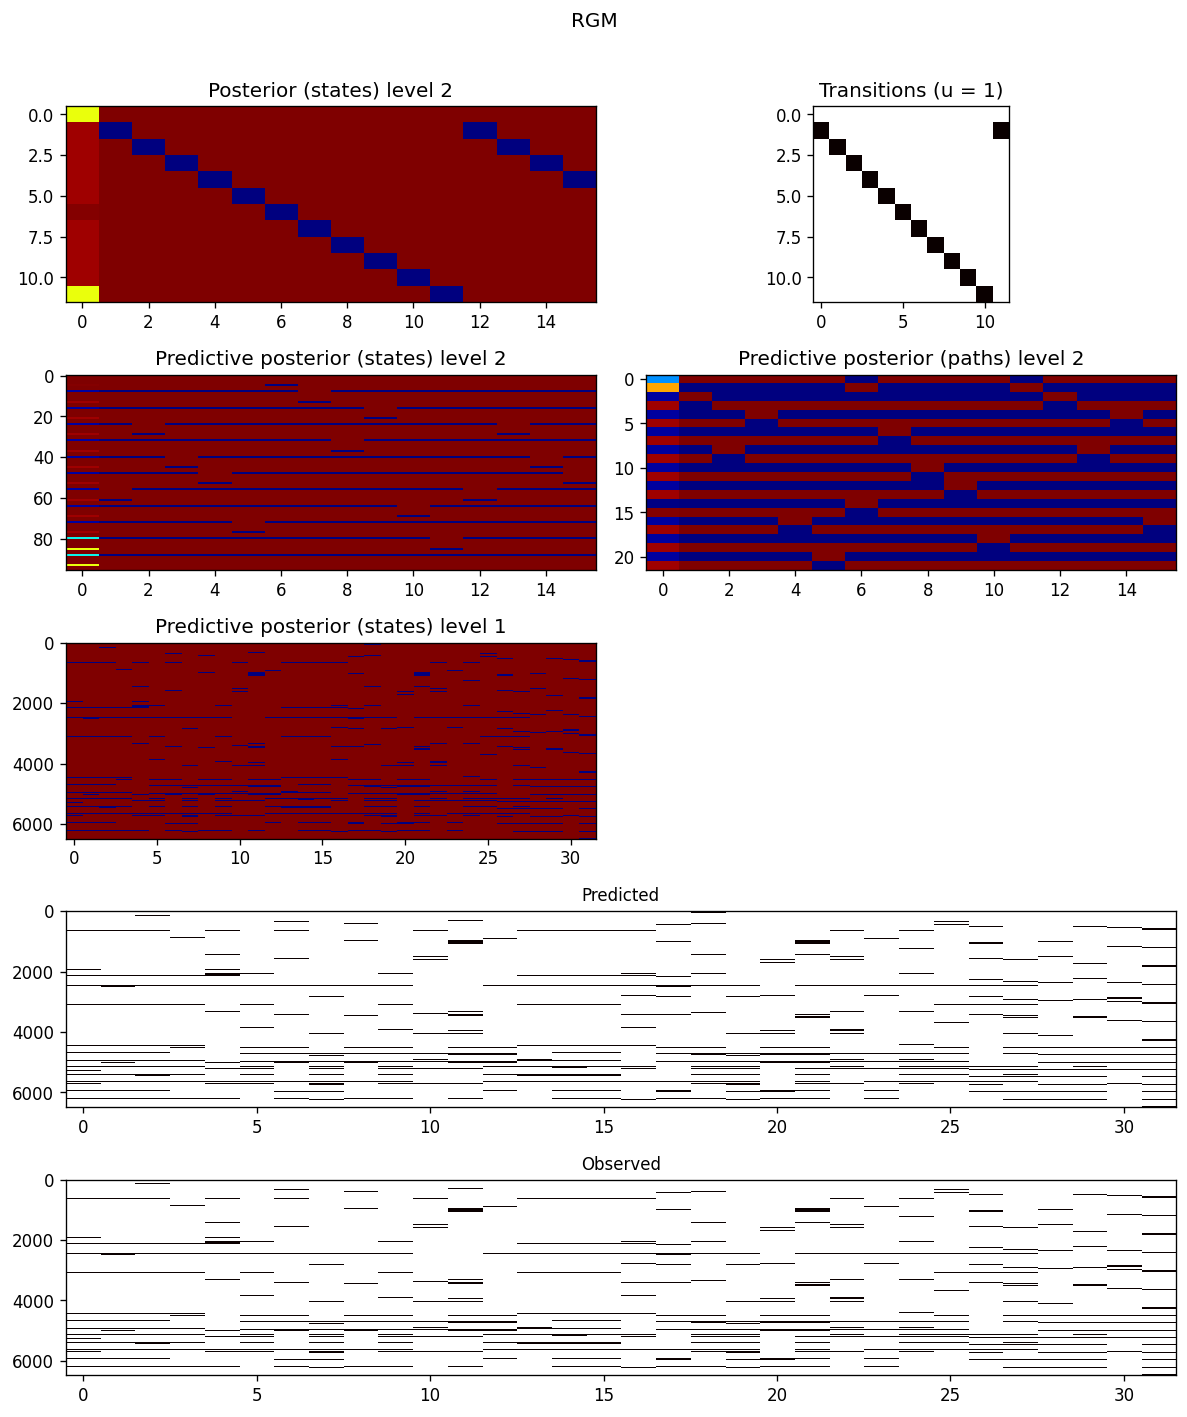

In [6]:
T_surveillance = 16

MDP_a2A = spm_mdp_a2A(_mdp_levels_for_a2A(MDP))

if isinstance(MDP_a2A, list):
    mdp_levels_in = MDP_a2A
else:
    arr = np.asarray(MDP_a2A, dtype=object).ravel(order="F")
    mdp_levels_in = [arr[i] for i in range(arr.size)]

mdp_p, mdp_levels, pack_meta = pack_mdp_ida_linked(mdp, mdp_levels_in, Nu=int(Nu))

RDP = spm_mdp2rdp([mdp_p] + list(mdp_levels[1:]))

RDP["T"] = float(T_surveillance)
RDP = spm_MDP_VB_XXX(RDP)

png_path = out_dir / "DEM_drone_VI_colab2_rgm.png"
written = dem_drone_vi_plot_rgm(RDP, save_png=True, png_path=png_path, fig_title="RGM")
assert written is not None and Path(written).is_file(), written
display(Image(filename=str(written)))

### Cell 6 — Active inference scene readout

Cell 5 inverted the coupled RGM over the surveillance horizon. This cell **reads out** level-1 beliefs into a plottable MDP and visualises the inferred scene—**not** a new hierarchical solve.

#### From recursive posterior to `QDP`

`Q_rec = RDP["Q"]` holds the nested posterior structure returned by `spm_MDP_VB_XXX`. Then

`QDP = spm_Q2mdp(Q_rec, 1)`

extracts the **level-1** beliefs into an MDP-like object **`QDP`** (categorical state/outcome fields suitable for the behaviour figure). Attaching

`QDP["id"] = mdp_p["id"]`

aligns modality and factor indices with the packed drone model from Cell 5, so depth/class/vision panels know which streams are which.

In paper language, the plotted quantities are posterior categoricals $\hat s$ (and related predictive outcomes) already computed under the hierarchical messages of Cell 5.

#### What “active inference” means in this figure

Here the phrase marks **beliefs about the scene after surveillance** under the coupled RGM—pose-dependent vision and place dynamics contextualised by deeper empirical priors—rather than a second planning problem. Wayfinding (next cell) will add explicit destination priors and re-solve.

#### Figure: active inference

`dem_drone_vi_plot_active_inference(QDP, PG, …)` draws the final-frame multi-panel behaviour figure from **`QDP`** and **`PG`** (same layout as wayfinding, **without** a goal overlay):

- **Inferred scene** (2D) and **inferred** 3D occupancy from posterior place beliefs;
- **True scene** panels for comparison where available in **`QDP`**;
- **Depth**, **Class**, and **Vision** panels from the ray/telemetry streams.

It is a visual check that surveillance produced coherent scene construction and exploration readouts before destination-directed planning.

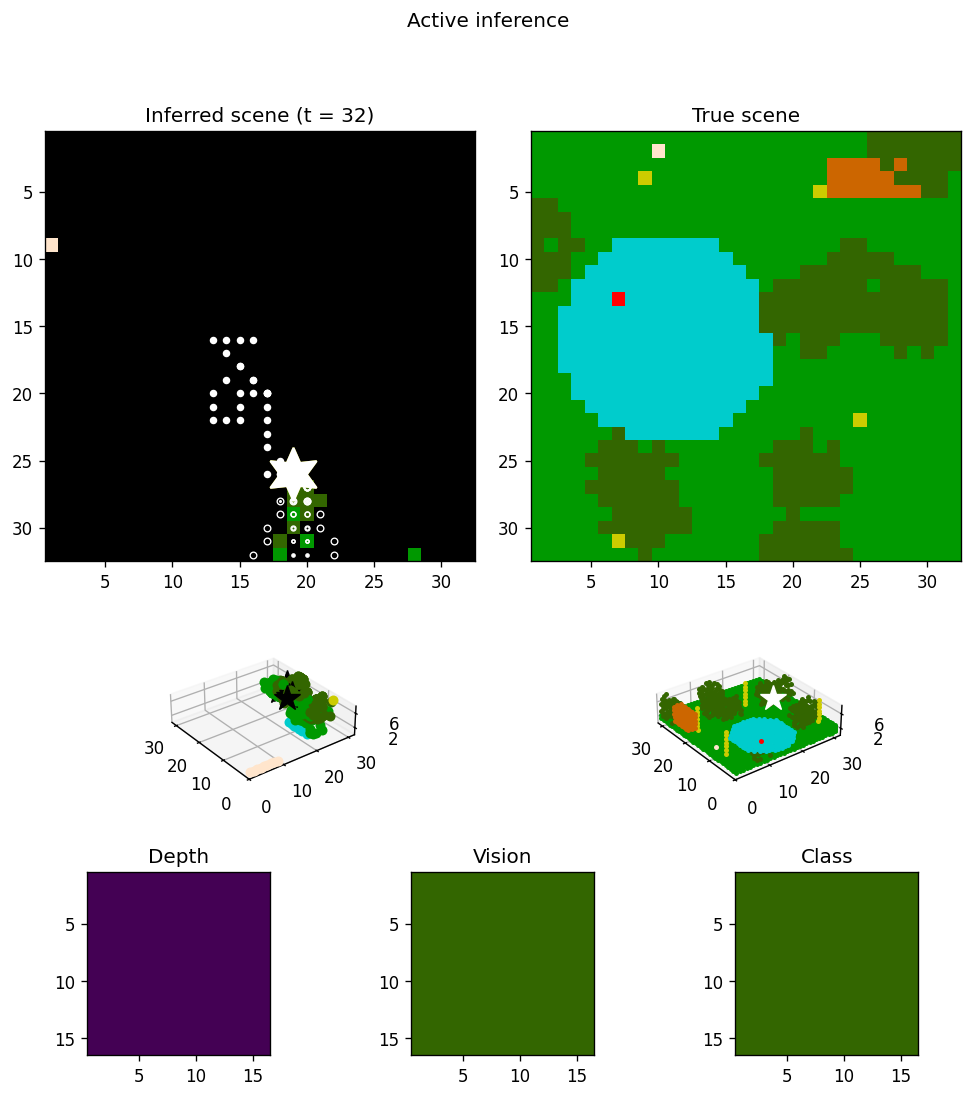

In [7]:
Q_rec = RDP["Q"]
QDP = spm_Q2mdp(Q_rec, 1)
QDP["id"] = mdp_p["id"]


png_path = out_dir / "DEM_drone_VI_colab2_active_inference.png"
written = dem_drone_vi_plot_active_inference(QDP, PG, save_png=True, png_path=png_path, fig_title="Active inference", )
assert written is not None and Path(written).is_file(), written
display(Image(filename=str(written)))

### Cell 7 — Wayfinding under destination priors

Surveillance (Cells 5–6) tracked dynamics in a known scene. This cell illustrates **pathfinding**: the agent is given precise priors over place latents (a cognitive map) and **delivery / goal** states, then plans a short horizon while keeping situational awareness of dynamic scene components.

#### Wayfinding vs surveillance

| | Surveillance | Wayfinding |
|---|--------------|------------|
| Level-0 model | packed **`mdp_p`** | **`pdp`** built from **`mdp_p`** with map + goals |
| Horizon | `T = 16` | `T = 4` |
| Extra prior | none beyond RGM coupling | place priors from **`MAP`**; goal **`sT`** |
| Readout | **`QDP`** | **`QDP_w`** |

Higher RGM levels are reused (`mdp_levels[1:]`) so place dynamics remain regularised by the same empirical priors.

#### Building `pdp` and goal `sT`

`pdp, sT = build_pdp_wayfinding(mdp_p, MAP, Nu=Nu, Np=Np)`

does two things:

1. **Cognitive map** — copies **`mdp_p`**, then sets place-factor priors **`pdp["D"][Nu : Nu+Np]`** from **`MAP`** (precise beliefs about the known inanimate scene at each place).
2. **Goal states** — writes destination indices into **`pdp["id"]["hid"]`**. The default goal in this demo is

$$
\texttt{sT}=[28,\,12,\,3]
$$

   (final hidden place coordinates on the grid). Preferences for planning now encode **where to go**, not a Pong-style reward stream.

#### Short-horizon recursive solve

`RDP_w = spm_mdp2rdp([pdp] + deepcopy(mdp_levels[1:]))` nests the wayfinding level 0 with the same deeper RGM levels. With **`RDP_w["T"] = 4`**,

`RDP_w = spm_MDP_VB_XXX(RDP_w)`

plans/infers under those priors. Then

`QDP_w = spm_Q2mdp(RDP_w["Q"], 1)` with `QDP_w["id"] = pdp["id"]`

extracts the level-1 readout for plotting (including the goal id).

#### Planning math (overview)

Controllable drone paths are scored by expected free energy. A one-step posterior-predictive form is

$$
G(k)
\approx
\underbrace{\sum_g D_{\mathrm{KL}}\!\big(\hat o^{g,k}_{\tau+1}\,\big\|\,p_{\mathrm{pref}}^g\big)}_{\text{risk}}
+
\underbrace{\sum_g \sum_{s_{\mathrm{pa}(g)}} Q_k(s_{\mathrm{pa}(g)})\,H_{\mathrm{amb}}^g(s_{\mathrm{pa}(g)})}_{\text{ambiguity}}
-
\underbrace{N(k)}_{\text{epistemic value}}.
$$

Path priors favour low $G$:

$$
q(k)=\operatorname{norm}_k\!\big(\pi_0(k)\,e^{-\alpha G(k)}\big).
$$

**In this cell**, $p_{\mathrm{pref}}$ / inductive constraints include the destination encoded by **`sT`** / **`pdp["id"]["hid"]`**, while deeper levels in **`RDP_w`** still supply empirical priors over place dynamics. `spm_MDP_VB_XXX` evaluates planning along the short horizon **`T_wayfinding = 4`**. (Local VMP message identities: see the Supplementary Material link in Cell 5.)

#### Figure: wayfinding

`dem_drone_vi_plot_wayfinding(QDP_w, PG, sT, …)` draws the same multi-panel behaviour layout as Cell 6 from **`QDP_w`** / **`PG`**, and overlays the goal **`sT`** on the inferred 2D scene. Compare to Cell 6: navigation is now biased toward the delivery location while the RGM keeps track of moving structure.

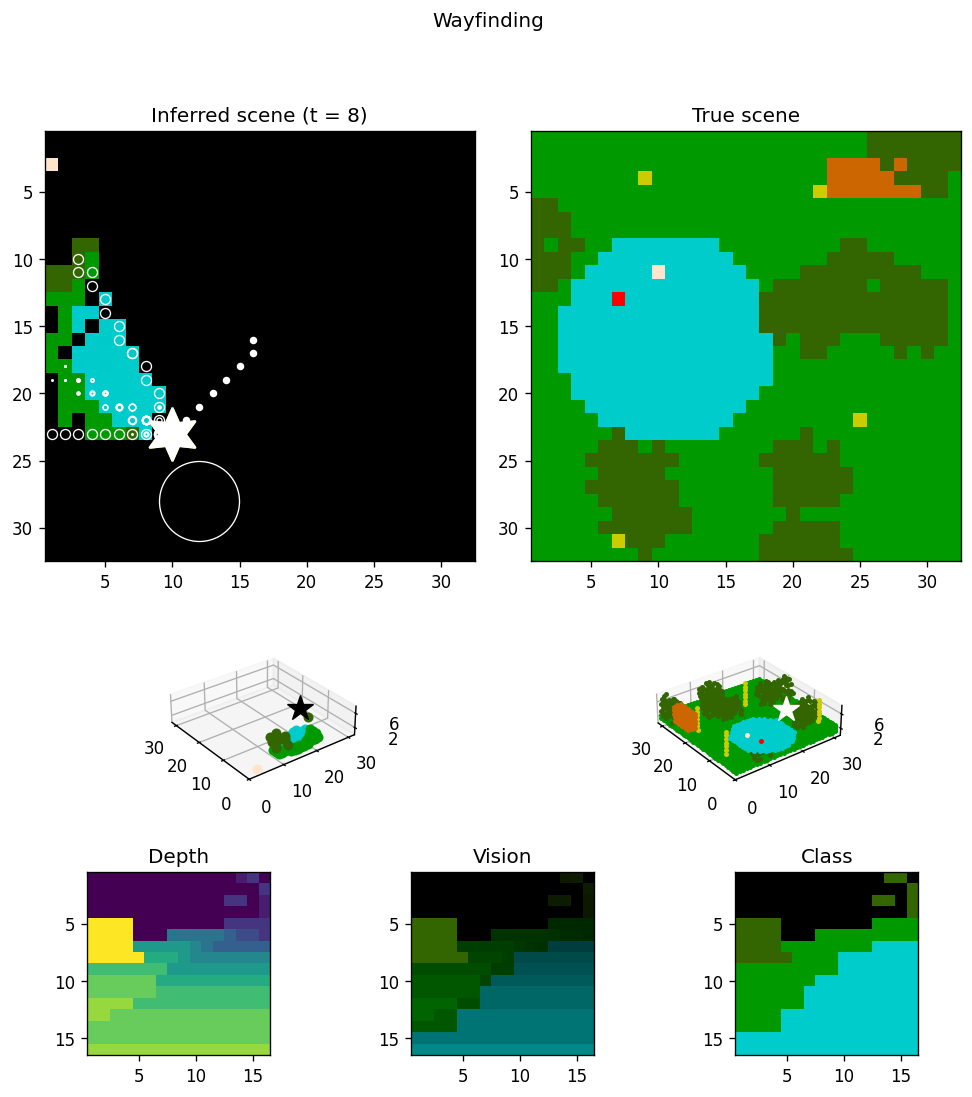

In [8]:
T_wayfinding = 4

pdp, sT = build_pdp_wayfinding(mdp_p, MAP, Nu=int(Nu), Np=int(Np), sT=None)

RDP_w = spm_mdp2rdp([pdp] + list(copy.deepcopy(mdp_levels[1:])))

RDP_w["T"] = float(T_wayfinding)
RDP_w = spm_MDP_VB_XXX(RDP_w)

QDP_w = spm_Q2mdp(RDP_w["Q"], 1)
QDP_w["id"] = pdp["id"]

png_path = out_dir / "DEM_drone_VI_colab2_wayfinding.png"
written = dem_drone_vi_plot_wayfinding(QDP_w, PG, sT, save_png=True, png_path=png_path, fig_title="Wayfinding", )
assert written is not None and Path(written).is_file(), written
display(Image(filename=str(written)))

### Cell 8 — Behaviour movie and wrap-up

#### What the movie is

`spm_behaviour(QDP_w, PG, sT, save_mp4=True, …)` replays the **same** wayfinding solution as Cell 7 frame by frame (inferred/true scenes, depth/class/vision panels, goal marker), and writes an MP4 (here at `fps=2`). Cell 7’s PNG was the final frame; this cell is the time-resolved visualisation of **`QDP_w`**, **`PG`**, and **`sT`**.

#### Wrap-up: Drone VI as an RGM pipeline

This notebook walked one end-to-end renormalising-generative-model story for active vision:

1. **Scene** — voxel world with categorical places (`W`, `MAP`).
2. **Process and model** — ray/pose-dependent functional likelihoods; **`GDP`** for generation, **`mdp`** for the drone scaffold.
3. **Data** — process play without drone exploration → place evidence **`Q`** ($Y^{(1)}$).
4. **Fast structure learning** — renormalisation $\mathcal{R}_n$ on the 3D lattice (`S`, `dx`) → hierarchy **`MDP`**.
5. **Couple** — link drone vision to RGM children (`a2A`, `pack_mdp_ida_linked`) → recursive **`RDP`**.
6. **Surveillance** — hierarchical VB; readout **`QDP`**.
7. **Wayfinding** — map priors + goal **`sT`**; short-horizon plan → **`QDP_w`**.
8. **Behaviour movie** — animated wayfinding readout.

Together, these steps show how RGMs supply **empirical priors over place and event dynamics** so an agent can see and plan in a **known dynamic environment**—with drone pose remaining controllable for surveillance and destination-directed navigation.

In [9]:
mp4_path = out_dir / "DEM_drone_VI_colab2_behaviour.mp4"
out = spm_behaviour(QDP_w, PG, sT, save_mp4=True, mp4_path=mp4_path, fig_title="Wayfinding", fps=2.0,)
assert out["mp4"] is not None and Path(out["mp4"]).is_file(), out
display(Video(str(out["mp4"]), embed=True, html_attributes="controls"))
